# 04. Diseño de validación y backtest: el laboratorio anti-fraude

Este cuaderno construye **únicamente el arnés de validación** que
blindará a los motores de los cuadernos 05 (baseline estadístico), 06
(estudio de capacidad Transformer) y 07 (grafo + optimización
genética). **No se entrena ningún modelo predictivo aquí**: se definen
las particiones espaciales, la compuerta de dominio, el protocolo de
abstención y las métricas de ranking que esos motores deberán
respetar.

**Qué evalúa el backtest.** La capacidad de un motor para
*redescubrir*, entre AGEBs que **ya tienen al menos una estación
interna**, las de mayor **actividad observada media por estación**.
Ocultamos temporalmente el resultado observado de un pliegue y
verificamos si el motor recupera las AGEBs relevantes en el top de su
ranking.

**Qué NO evalúa.** No valida demanda latente en territorio sin
servicio: una AGEB sin estaciones no tiene etiqueta observada y no
puede contarse como positivo ni como negativo. Tampoco produce
métricas de desempeño de motor: el único ejecutor que recorre los
pliegues en este cuaderno es un control aleatorio de plomería del
arnés.

**Aclaración de alcance.** El antiguo Motor 2 de series de tiempo
(stock-outs y saturación) queda **oficialmente descartado** de la
tesis. La arquitectura vigente alimenta a los motores **en paralelo**:
este cuaderno entrega a los cuadernos 05, 06 y 07 el mismo arnés y el
mismo contrato de despliegue; los tres resuelven **la misma tarea**
—un portafolio de B sitios bajo reglas de red comunes— con métodos
distintos y **sin leer las salidas de otro motor**. En consecuencia
**no se diseñan validaciones temporales**: todo el esfuerzo de
validación es espacial y de dominio.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown, JSON

BASE = Path.cwd().resolve()
PROJECT = next(p / "4_proyecto" for p in [BASE, *BASE.parents] if (p / "4_proyecto/V3/data").is_dir())
V3_DIR = PROJECT / "V3"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from V3.src.fe04_analysis import CONFIG, TARGET, load_inputs, analyze
from V3.src.fe04_publication import stage_results

GREEN, GRAY, BLUE, RED = "#004731", "#546E7A", "#0D47A1", "#B03A2E"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
data = load_inputs(V3_DIR)
result = analyze(data)
report = result["report"]
universe, folds = result["universe"], result["folds"]
display(pd.DataFrame([{
    "contract_id": report["contract_id"],
    "analysis_version": report["schema_version"],
    "feature_analysis_id": report["upstream"]["feature_analysis_id"],
    "eda_analysis_id": report["upstream"]["eda_analysis_id"],
    "pca_space_k": report["upstream"]["pca_space_k"],
    "evaluation_universe": report["evaluation_universe"]["size"],
    "target": TARGET,
}]))

,contract_id,analysis_version,feature_analysis_id,eda_analysis_id,pca_space_k,evaluation_universe,target
0,6e586b3d9a0bd8b844d9cf5bc714f0e583fc2a6936f8cd...,v3-backtest-4,7565adda3bc4eb91514247d2a1213f0b1c934821e762ac...,d77ab12f05e9025f438921b34e8688e1a7562826296427...,8,242,actividad_media_estacion


## 1. Universo de evaluación y verdad-terreno

El universo evaluable son las AGEBs **proyectables, no candidatas
territoriales y con al menos una estación interna**: solo allí existe
una tasa de uso observada con la que calificar un ranking.

**Media, no suma.** La verdad-terreno es la **actividad media por
estación** (`actividad_media_estacion`), no la actividad total del
polígono. Las dos cantidades difieren materialmente: la correlación de
rangos de Spearman de cada una con el número de estaciones se reporta
abajo. Usar la suma premiaría mecánicamente a las AGEBs con más
estaciones —un correlato de inversión histórica, no de desempeño
unitario— mientras que la media por estación es el análogo escalar del
objetivo de colocación.

**Roles, no etiquetas inventadas.** Cada AGEB tiene un
`evaluation_role`. Las AGEBs servidas evaluables son
`labeled_served`; las servidas que no pueden evaluarse (p. ej. no
proyectables) son `served_not_evaluable`; las candidatas sin estación
son `candidate_unlabeled` o `covered_without_station_unlabeled`. Una
AGEB sin estación es **sin etiqueta**, nunca un negativo: cero
observado no es demanda latente cero y el arnés no rellena ceros.

**Golden-03 vs. referencia de pliegue.** Las banderas Golden del
cuaderno 03 describen la referencia descriptiva global; en este
cuaderno se contrastan estadísticamente con el resto del universo,
pero **quedan prohibidas como insumo del motor** porque fueron
calculadas con información que puede incluir filas de validación. En
cada pliegue, el motor deberá reconstruir su referencia solo con
entrenamiento (sección 5).

In [2]:
ev = report["evaluation_universe"]
display(pd.Series({k: v for k, v in ev.items()
                   if not isinstance(v, dict)}, name="valor").to_frame())
display(pd.Series(ev["golden_reference_relation"],
                  name="valor").to_frame())
display(universe.evaluation_role.value_counts().to_frame("n_ageb"))
display(universe.loc[universe.in_evaluation_universe,
                     ["n_estaciones", "actividad_total_diaria",
                      "actividad_media_estacion"]].describe().T)

,valor
definition,is_projectable AND n_estaciones > 0 AND NOT is...
size,242
target,actividad_media_estacion
target_definition,mean viajes_diarios_prom of stations hosted by...
why_mean_not_sum,the AGEB sum grows with station count; the mea...
target_spearman_with_station_count,0.178716
sum_spearman_with_station_count,0.776615
covered_without_station_treatment,excluded from labels; their absence of station...
label,target >= P85 fitted on the retained TRAIN row...
gain_for_ndcg,linear actividad_media_estacion


,valor
golden_03_definition,AGEB hosting >=1 station above the station-lev...
golden_in_universe,61
golden_mean_target,129.884472
non_golden_mean_target,58.66738
note,Golden labels use test-fold stations in their ...


,n_ageb
evaluation_role,
candidate_unlabeled,2111
labeled_served,242
covered_without_station_unlabeled,98
served_not_evaluable,1


,count,mean,std,min,25%,50%,75%,max
n_estaciones,242.0,2.793388,1.515712,1.000000,2.000000,2.000000,4.000000,7.000000
actividad_total_diaria,242.0,227.630211,210.198834,26.063014,92.625685,148.057534,292.403767,1174.654795
actividad_media_estacion,242.0,76.618796,40.327857,12.552968,48.385616,66.226712,94.518379,219.445205


## 2. Compuerta de dominio: distancia de Mahalanobis calibrada

Una AGEB solo es **matemáticamente evaluable** si cae dentro del
soporte estadístico de la referencia Golden. La compuerta es
**global y descriptiva**: se ajusta la covarianza **empírica** del
cluster en el espacio PCA compartido publicado por el cuaderno 03 —la
ortogonalidad global del PCA **no** implica covarianza diagonal dentro
del subconjunto Golden— y se calibra el umbral con
$\sqrt{\chi^2_{k}(0.9973)}$.

**Sin pseudoinversa.** Una covarianza singular o casi singular hace
que la distancia deje de estar definida: el ajuste **rechaza** esos
casos en lugar de resolverlos con una pseudoinversa opaca. El número
de condición y el eigenvalor mínimo quedan publicados.

**Empírico vs. Ledoit-Wolf.** La compuerta descriptiva de este cuaderno
sigue siendo la empírica. A título de diagnóstico se ajusta también la
covarianza **Ledoit-Wolf** (encogimiento hacia la diagonal escalada)
sobre la misma referencia y se comparan número de condición,
encogimiento estimado y conteo en dominio. Dos notas honestas: el
encogimiento estabiliza la covarianza cuando la referencia es pequeña
frente a la dimensión ($n/p \approx 3$); y con encogimiento el umbral
χ² es **nominal**, porque las distancias de entrenamiento ya no
siguen exactamente una $\chi^2_k$. Los motores que usen referencias
pequeñas (como el Motor 1) podrán optar por el estimador
`ledoit_wolf` de la misma función publicada.

`in_domain = True` no significa «recomendable»: significa «la
referencia tiene soporte para compararla», y `out_of_domain` **no es
evidencia de una mala ubicación** —solo de extrapolación fuera del
soporte calibrado. Que la mayoría de las AGEBs Golden queden dentro
es una comprobación descriptiva de consistencia, **no** una prueba de
calibración: la calibración χ² asume scores aproximadamente elípticos
y sigue pendiente de validación formal.

,valor
scope,global descriptive gate referenced to the 61 G...
k_dims,8
n_reference,61
covariance_rank,8
singular_covariance_policy,rejected (no pseudoinverse)
min_eigenvalue,0.22209
condition_number,14.324825
quantile,0.9973
df,8
chi2_ppf,23.574394


**Comparación de estimadores de covarianza** (compuerta descriptiva; el gate sigue empírico)

,empirical,ledoit_wolf
condition_number,14.324825,4.969608
covariance_rank,8.000000,8.000000
in_domain_count,1057.000000,1382.000000
shrinkage,NaN,0.299575


descriptive comparison over the Golden gate, which stays empirical; the chi-square threshold is nominal under shrinkage (train distances no longer follow chi2_k exactly)

,n_ageb
out_of_domain,1345
in_domain,1057
not_projectable,50


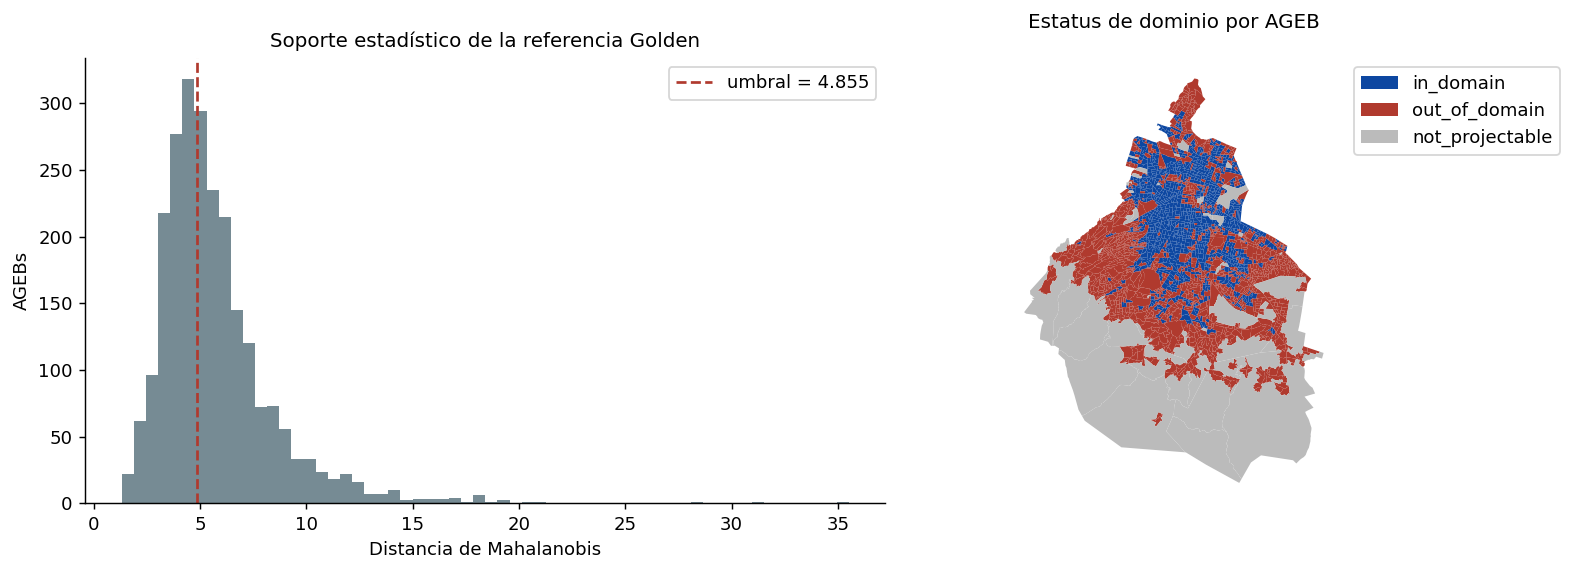

In [3]:
gate = report["mahalanobis_gate"]
display(pd.Series({k: v for k, v in gate.items()
                   if not isinstance(v, dict)}, name="valor").to_frame())
display(Markdown("**Comparación de estimadores de covarianza** "
                 "(compuerta descriptiva; el gate sigue empírico)"))
cmp_est = {k: v for k, v in
           gate["covariance_estimator_comparison"].items()
           if isinstance(v, dict)}
display(pd.DataFrame(cmp_est))
display(Markdown(gate["covariance_estimator_comparison"]["note"]))
display(pd.Series(gate["in_domain_counts"],
                  name="n_ageb").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
dists = universe.mahalanobis_distance.dropna()
axes[0].hist(dists, bins=60, color=GRAY, alpha=0.8)
axes[0].axvline(gate["threshold"], color=RED, ls="--",
                label=f"umbral = {gate['threshold']:.3f}")
axes[0].set(xlabel="Distancia de Mahalanobis", ylabel="AGEBs",
            title="Soporte estadístico de la referencia Golden")
axes[0].legend()
status_colors = {"in_domain": BLUE, "out_of_domain": RED,
                 "not_projectable": "#BBBBBB"}
for status, color in status_colors.items():
    subset = universe.loc[universe.domain_status == status]
    if len(subset):
        subset.plot(ax=axes[1], color=color, edgecolor="none")
axes[1].legend(handles=[
    Patch(facecolor=c, label=s) for s, c in status_colors.items()],
    loc="upper left", bbox_to_anchor=(1.02, 1))
axes[1].set_axis_off()
axes[1].set_title("Estatus de dominio por AGEB")
plt.tight_layout(); plt.show()

## 3. Validación cruzada espacial honesta

Se publican **dos esquemas de partición** sobre el universo de
evaluación:

- **`fold_groupkfold_ageb`**: `GroupKFold` agrupado por `cvegeo`. Es
  la **referencia optimista**: impide que una misma AGEB se reparta
  entre pliegues, pero **no aísla polígonos vecinos** —la tabla de
  separación muestra que las AGEBs urbanas son adyacentes
  (distancia mínima inter-pliegue de 0 m), por lo que la dependencia
  espacial residual infla el desempeño aparente.
- **`fold_spatial_block`**: `GroupKFold` sobre **bloques espaciales
  contiguos** producidos por **clustering aglomerativo Ward con
  restricción de conectividad poligonal**: el grafo de adyacencia
  conecta solo AGEBs colindantes (distancia poligonal ≤ 1 m en el CRS
  métrico) y Ward solo puede fusionar vecinos del grafo, así que cada
  bloque es geográficamente coherente. Determinista, sin semilla.
  Si el grafo del universo evaluado está fragmentado, sklearn
  completa la conectividad y un bloque puede reunir islas separadas:
  `n_adjacency_components` y `blocks_contiguous_share` publican ese
  diagnóstico —no se declara contigüidad estricta global cuando el
  universo no es un solo componente.

El esquema **primario** es `fold_spatial_block` combinado con un
**buffer de 500 m**: para cada pliegue se excluyen además del
entrenamiento todas las AGEBs a 500 m o menos del frente de prueba
(exclusiones recomputadas desde la geometría, por pliegue). **La
ausencia de fuga por colindancia la garantiza el buffer, no la
contigüidad de los bloques**: la tabla de separación cuenta los pares
prueba–entrenamiento colindantes antes y después del buffer, y el
arnés **falla** si sobrevive alguno tras él.

,valor
n_folds,5
evaluation_universe_size,242
n_spatial_blocks,15
n_adjacency_components,1
blocks_contiguous_share,1.0
n_blocks,15
primary_scheme,fold_spatial_block
groupkfold_ageb_note,at AGEB granularity equals shuffled KFold; no ...
spatial_block_note,Ward agglomerative clustering on centroids wit...
buffer_m,500


,fold_sizes_groupkfold_ageb,fold_sizes_spatial_block
0,49,55
1,49,39
2,48,47
3,48,52
4,48,49


,n_excluded_total
fold_spatial_block,278


**Contigüidad de los bloques** (componentes conexos del grafo de colindancia dentro de cada bloque)

,n_components
0,1
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


**Separación prueba–entrenamiento por pliegue** (distancia mínima y pares colindantes antes/después del buffer; en `fold_spatial_block` el arnés exige 0 pares tras el buffer)

,fold_scheme,fold,n_test,n_train_retained,n_buffer_excluded,min_train_test_distance_m,train_within_buffer,touching_train_test_pairs_before_buffer,touching_train_test_pairs_after_buffer
0,fold_groupkfold_ageb,0,49,193,0,0.000000,180,220,220
1,fold_groupkfold_ageb,1,49,193,0,0.000000,177,232,232
2,fold_groupkfold_ageb,2,48,194,0,0.000000,189,206,206
3,fold_groupkfold_ageb,3,48,194,0,0.000000,178,214,214
4,fold_groupkfold_ageb,4,48,194,0,0.000000,183,216,216
5,fold_spatial_block,0,55,117,70,500.583149,0,95,0
6,fold_spatial_block,1,39,150,53,508.322951,0,57,0
7,fold_spatial_block,2,47,139,56,502.632218,0,59,0
8,fold_spatial_block,3,52,136,54,505.049535,0,50,0
9,fold_spatial_block,4,49,148,45,506.370875,0,59,0


**Exclusiones por buffer de 500 m** — filas de entrenamiento descartadas por pliegue

n_excluded
fold_scheme        fold            
fold_spatial_block 0             70
                   1             53
                   2             56
                   3             54
                   4             45

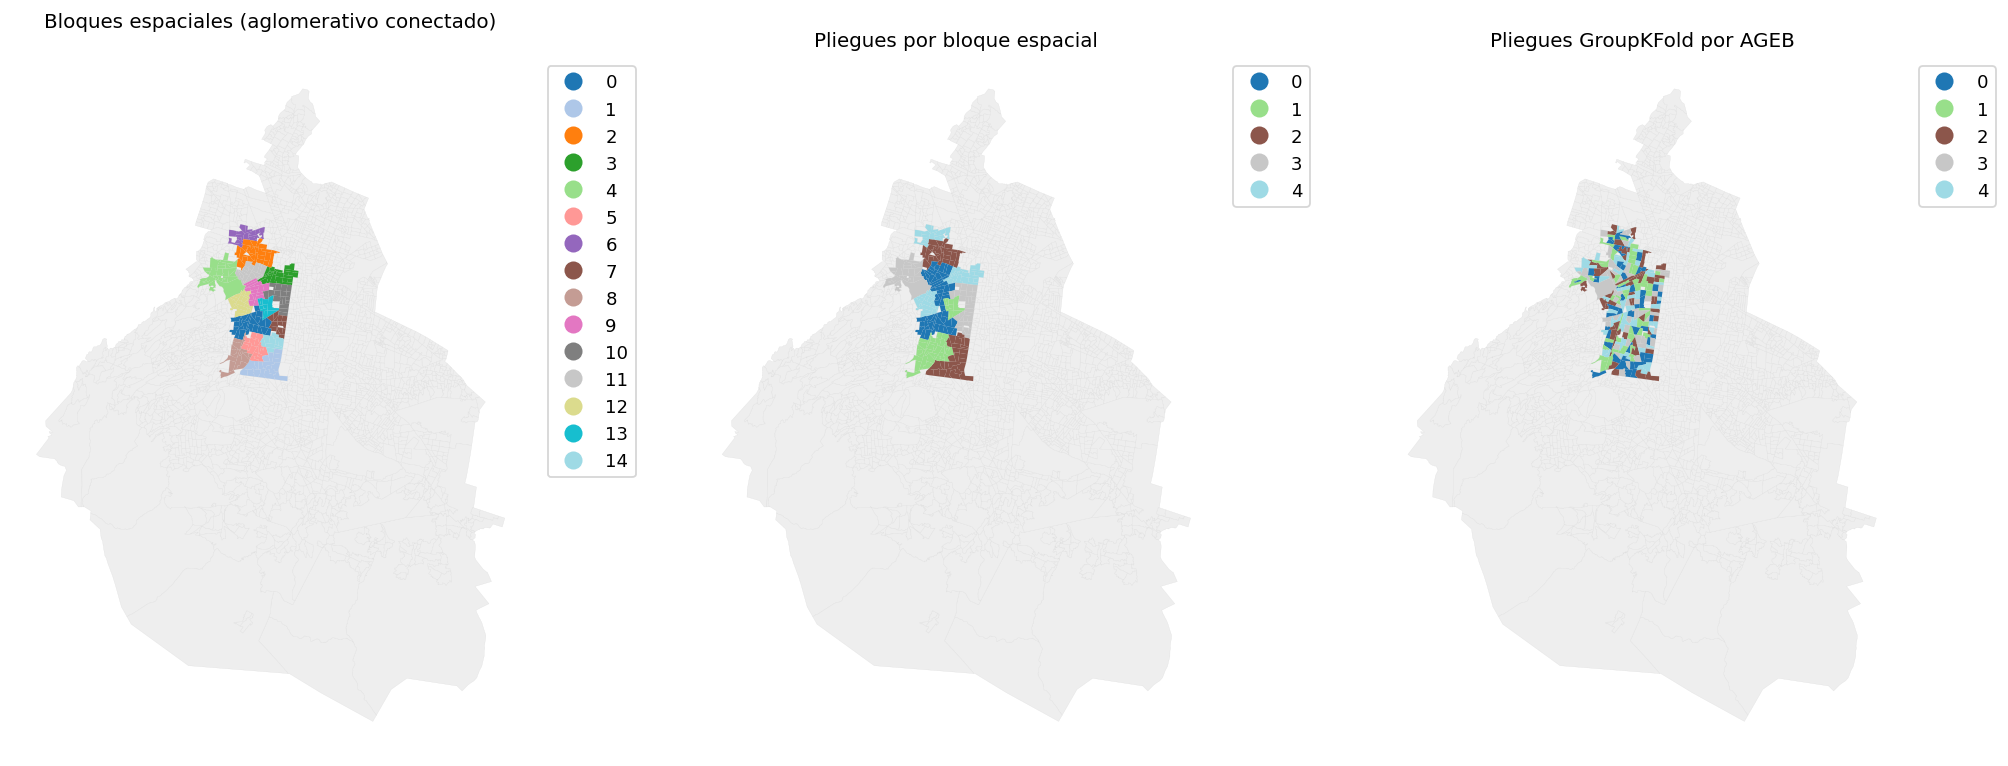

In [4]:
scv = report["spatial_cv"]
display(pd.Series({k: v for k, v in scv.items()
                   if not isinstance(v, (dict, list))},
                  name="valor").to_frame())
display(pd.DataFrame({
    "fold_sizes_groupkfold_ageb": scv["fold_sizes_groupkfold_ageb"],
    "fold_sizes_spatial_block": scv["fold_sizes_spatial_block"]}))
display(pd.Series(scv["buffer_exclusions_by_scheme"],
                  name="n_excluded_total").to_frame())
display(Markdown("**Contigüidad de los bloques** (componentes conexos "
                 "del grafo de colindancia dentro de cada bloque)"))
display(pd.Series(scv["components_per_block"],
                  name="n_components").to_frame())
display(Markdown("**Separación prueba–entrenamiento por pliegue** "
                 "(distancia mínima y pares colindantes "
                 "antes/después del buffer; en `fold_spatial_block` "
                 "el arnés exige 0 pares tras el buffer)"))
display(pd.DataFrame(scv["separation"]))
display(Markdown("**Exclusiones por buffer de "
                 f"{int(scv['buffer_m'])} m** — filas de "
                 "entrenamiento descartadas por pliegue"))
bex = result["buffer_exclusions"]
if len(bex):
    display(bex.groupby(["fold_scheme", "fold"]).size()
              .to_frame("n_excluded"))
else:
    display(Markdown("_Sin exclusiones._"))
eval_g = universe.loc[universe.in_evaluation_universe].merge(
    folds[["cvegeo", "fold_spatial_block", "fold_groupkfold_ageb"]],
    on="cvegeo")
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, col, title in [
        (axes[0], "spatial_block_id",
         "Bloques espaciales (aglomerativo conectado)"),
        (axes[1], "fold_spatial_block", "Pliegues por bloque espacial"),
        (axes[2], "fold_groupkfold_ageb",
         "Pliegues GroupKFold por AGEB")]:
    universe.plot(ax=ax, color="#EEEEEE", edgecolor="#DDDDDD",
                  linewidth=0.15)
    eval_g.plot(ax=ax, column=col, cmap="tab20", edgecolor="none",
                categorical=True, legend=True,
                legend_kwds={"loc": "upper left",
                             "bbox_to_anchor": (1.02, 1)})
    ax.set_axis_off(); ax.set_title(title)
plt.tight_layout(); plt.show()

## 4. Métricas de ranking, abstención y auto-pruebas

Los motores producirán un **ranking del universo del pliegue**; el
arnés lo califica con `Precision@K`, `Recall@K`, `Precision_cond@K` y
`NDCG@K` sobre la rejilla publicada:

- **Precision@K** $= |R \cap \mathrm{top}\,K| / K_{\mathrm{eff}}$ con
  $K_{\mathrm{eff}} = \min(K, |\mathrm{universe}|)$ —el denominador es
  fijo por el universo declarado del pliegue, **no** por lo que el
  motor decidió rankear.
- **Recall@K** $= |R \cap \mathrm{top}\,K| / |R|$ con $R$ fijado por
  el umbral P85 del **entrenamiento**; la abstención **no reduce** el
  denominador. Si el pliegue no tiene relevantes, el recall es
  `NaN` —se reporta explícitamente, no se oculta ni se convierte en
  cero.
- **Precision_cond@K**: precisión condicionada a recomendar —
  $|R \cap \mathrm{top}\,K| / |\mathrm{ranked} \cap \mathrm{top}\,K|$;
  mide la calidad de lo recomendado sin premiar la abstención.
- **NDCG@K**: ganancias lineales sobre la actividad observada,
  descuento log₂(posición+1), acotado en [0,1]. Es la métrica
  **incondicional primaria**: el IDCG usa todo el universo del
  pliegue, así que abstenerse sobre una AGEB de alta ganancia baja
  el numerador sin bajar el denominador.
- **NDCG_cond@K**: igual, pero el IDCG se calcula **solo sobre los
  IDs efectivamente rankeados** (los abstenidos no entran al
  denominador). No penaliza abstenciones y por eso **puede premiar
  una compuerta que se abstiene en los casos difíciles**: siempre se
  lee junto con `decision_coverage`.

**Abstención.** Un motor puede devolver `{"ranked", "abstained"}`:
rankear un subconjunto y declarar abstención explícita en el resto del
pliegue —es la **única** forma de entregar un ranking parcial;
`run_backtest` **rechaza** una lista que no sea la permutación
completa de las AGEBs de prueba. En la evaluación, toda AGEB no
rankeada cuenta como abstenida: ninguna omisión puede inflar el
recall porque los denominadores están fijados por el universo y los
relevantes declarados del pliegue. La tabla de decisión publicada
distingue `ranked` de `abstained` y reporta la **cobertura de
decisión** por pliegue junto a los relevantes abstenidos.

Antes de confiar en el laboratorio, el laboratorio se examina a sí
mismo: la familia **metric** fija respuestas conocidas (incluidos los
casos límite de abstención, omisión y pliegues sin relevantes) y la
familia **harness** verifica el comportamiento extremo a extremo del
ejecutor. El **control aleatorio** sobre los pliegues reales es una
prueba de plomería (Precision@K debe rondar la tasa base), **no un
resultado de motor**.

In [5]:
display(pd.Series({k: v for k, v in report["ranking_metrics"].items()
                   if not isinstance(v, dict)},
                  name="valor").to_frame())
display(Markdown("**K efectivo por pliegue y esquema**"))
for scheme, cols in report["ranking_metrics"][
        "effective_k_by_fold"].items():
    display(pd.DataFrame(cols).rename_axis("fold"))
st = result["selftests"]
display(st.groupby("family")["pass"].agg(
    pruebas="count", aprobadas="sum"))
for family, sub in st.groupby("family"):
    display(Markdown(f"**Auto-pruebas — familia `{family}`**"))
    display(sub.drop(columns="family"))
for scheme, detail in result["random_detail"].items():
    summary = result["random_summary"][scheme]
    n_zero = int(detail.n_relevant.eq(0).sum())
    display(Markdown(f"**Control aleatorio — {scheme}** "
                     "(plomería, no línea base); "
                     f"{n_zero} pliegue(s) sin relevantes "
                     "(recall = NaN, reportado sin ocultar)"))
    kcols = [c for c in detail.columns
             if c.startswith(("precision@", "recall@", "ndcg@",
                              "ndcg_cond@", "precision_cond@",
                              "effective_k@"))]
    display(detail[["fold", "n_train_used", "n_buffer_excluded",
                    "n_universe", "n_ranked", "n_abstained",
                    "decision_coverage", "n_relevant",
                    "relevant_abstained"] + kcols])
    display(summary[["mean", "std", "min", "max"]])

,valor
k_grid,"[10, 20, 50]"
precision_at_k,"|top-K ∩ relevant| / K_eff, K_eff = min(K, |fo..."
recall_at_k,|top-K ∩ relevant| / |relevant in fold| (NaN i...
ndcg_at_k,"linear gains, log2(position+1) discount, IDCG ..."
ndcg_cond_at_k,IDCG over the effectively ranked set only: doe...
precision_cond_at_k,"hits / min(K_eff, |ranked|): quality among rec..."
abstention,unranked test IDs count as abstained: they nev...
input_validation,"duplicate, foreign or missing IDs are rejected"
selftests_all_passed,True
n_selftests,42


**K efectivo por pliegue y esquema**

,effective_k@10,effective_k@20,effective_k@50
fold,,,
0,10,20,49
1,10,20,49
2,10,20,48
3,10,20,48
4,10,20,48


,effective_k@10,effective_k@20,effective_k@50
fold,,,
0,10,20,50
1,10,20,39
2,10,20,47
3,10,20,50
4,10,20,49


,pruebas,aprobadas
family,,
harness,10,10
metric,32,32


...

,fold,n_train_used,n_buffer_excluded,n_universe,n_ranked,n_abstained,decision_coverage,n_relevant,relevant_abstained,effective_k@10,...,recall@20,ndcg@20,ndcg_cond@20,precision_cond@20,effective_k@50,precision@50,recall@50,ndcg@50,ndcg_cond@50,precision_cond@50
0,0,193,0,49,49,0,1.0,7,0,10,...,0.571429,0.657986,0.657986,0.20,49,0.142857,1.0,0.831480,0.831480,0.142857
1,1,193,0,49,49,0,1.0,10,0,10,...,0.300000,0.496518,0.496518,0.15,49,0.204082,1.0,0.762901,0.762901,0.204082
2,2,194,0,48,48,0,1.0,8,0,10,...,0.500000,0.547720,0.547720,0.20,48,0.166667,1.0,0.781670,0.781670,0.166667
3,3,194,0,48,48,0,1.0,4,0,10,...,0.250000,0.653754,0.653754,0.05,48,0.083333,1.0,0.857127,0.857127,0.083333
4,4,194,0,48,48,0,1.0,7,0,10,...,0.285714,0.593686,0.593686,0.10,48,0.145833,1.0,0.817891,0.817891,0.145833


,mean,std,min,max
decision_coverage,1.000000,0.000000,1.000000,1.000000
relevant_abstained,0.000000,0.000000,0.000000,0.000000
effective_k@10,10.000000,0.000000,10.000000,10.000000
precision@10,0.220000,0.083666,0.100000,0.300000
recall@10,0.307857,0.092940,0.200000,0.428571
ndcg@10,0.535693,0.094908,0.410041,0.620759
ndcg_cond@10,0.535693,0.094908,0.410041,0.620759
precision_cond@10,0.220000,0.083666,0.100000,0.300000
effective_k@20,20.000000,0.000000,20.000000,20.000000
precision@20,0.140000,0.065192,0.050000,0.200000


**Control aleatorio — fold_spatial_block** (plomería, no línea base); 0 pliegue(s) sin relevantes (recall = NaN, reportado sin ocultar)

,fold,n_train_used,n_buffer_excluded,n_universe,n_ranked,n_abstained,decision_coverage,n_relevant,relevant_abstained,effective_k@10,...,recall@20,ndcg@20,ndcg_cond@20,precision_cond@20,effective_k@50,precision@50,recall@50,ndcg@50,ndcg_cond@50,precision_cond@50
0,0,117,70,55,55,0,1.0,26,0,10,...,0.384615,0.655676,0.655676,0.50,50,0.460000,0.884615,0.819965,0.819965,0.460000
1,1,150,53,39,39,0,1.0,2,0,10,...,0.500000,0.635076,0.635076,0.05,39,0.051282,1.000000,0.792857,0.792857,0.051282
2,2,139,56,47,47,0,1.0,3,0,10,...,0.333333,0.564355,0.564355,0.05,47,0.063830,1.000000,0.801296,0.801296,0.063830
3,3,136,54,52,52,0,1.0,8,0,10,...,0.250000,0.621799,0.621799,0.10,50,0.160000,1.000000,0.842072,0.842072,0.160000
4,4,148,45,49,49,0,1.0,19,0,10,...,0.263158,0.611999,0.611999,0.25,49,0.387755,1.000000,0.859838,0.859838,0.387755


,mean,std,min,max
decision_coverage,1.000000,0.000000,1.000000,1.000000
relevant_abstained,0.000000,0.000000,0.000000,0.000000
effective_k@10,10.000000,0.000000,10.000000,10.000000
precision@10,0.260000,0.230217,0.100000,0.600000
recall@10,0.279926,0.143631,0.125000,0.500000
ndcg@10,0.580560,0.059344,0.510661,0.635810
ndcg_cond@10,0.580560,0.059344,0.510661,0.635810
precision_cond@10,0.260000,0.230217,0.100000,0.600000
effective_k@20,20.000000,0.000000,20.000000,20.000000
precision@20,0.190000,0.191703,0.050000,0.500000


## 5. Protocolo de reajuste por pliegue, interfaz del motor y publicación

Regla normativa para los cuadernos de motores: en la fase inductiva,
**todo** estimador de preprocesamiento y referencia se ajusta solo con
entrenamiento —imputador, escalador, PCA, umbral P85, centroide
$\mu_{\text{Golden}}$ y covarianza $\Sigma_g$— y se aplica como
transformación a validación. Reutilizar el PCA global del cuaderno 03
o las banderas Golden como insumo del motor es **fuga transductiva**.

**Interfaz del motor.** `run_backtest` entrega a cada motor un
diccionario de tarea con `fold_scheme`, `fold`, `train_ids`,
`train_target` (solo etiquetas de entrenamiento), `test_ids` (sin
etiquetas) y `fit_exclusion_ids` (prueba ∪ buffer: las filas vedadas
a todo ajuste); el motor devuelve una permutación completa del
universo del pliegue o el contrato de abstención. Cualquier identificador ajeno, duplicado u
omisión no declarada invalida el pliegue.

Se publican: el universo de evaluación con sus roles y banderas de
dominio, las asignaciones de pliegues y bloques, las exclusiones por
buffer, los diagnósticos de separación, las auto-pruebas y el paquete
serializado del arnés —parámetros calibrados, particiones, separadores
no ajustados y las funciones del módulo ligadas por referencia y por
hash de código a esta auditoría.

In [6]:
proto = report["fold_local_protocol"]
display(Markdown(f"**Protocolo.** {proto['description']} "
                 f"**Interfaz.** {proto['engine_interface']}"))
display(pd.DataFrame({"refit_inside_each_training_fold":
                      proto["refit_inside_each_training_fold"]}))
display(pd.DataFrame({"applied_as_transform_to_validation":
                      proto["applied_as_transform_to_validation"]}))
display(pd.DataFrame({"forbidden": proto["forbidden"]}))
display(pd.Series({"engine_task_fields":
                   "fold_scheme, fold, train_ids, train_target, "
                   "test_ids, fit_exclusion_ids",
                   "serialization": report["serialization"]},
                  name="valor").to_frame())
display(pd.DataFrame({"pending_validation": report["pending_validation"]}))

**Protocolo.** Todo estimador de preprocesamiento y referencia se ajusta exclusivamente con filas fuera de fit_exclusion_ids (prueba ∪ buffer) del pliegue. **Interfaz.** engine_fn(task) -> list (ranking completo) o {'ranked': [...], 'abstained': [...]} que particionen exactamente task['test_ids']

,refit_inside_each_training_fold
0,SimpleImputer(strategy='median') sobre las tas...
1,StandardScaler
2,"PCA (n_components=0.80, svd_solver='full'); k ..."
3,Umbral P85 del objetivo para la referencia de ...
4,Centroide y covarianza de la referencia de ent...
5,"Umbral de dominio sqrt(chi2.ppf(0.9973, df=k_f..."


,applied_as_transform_to_validation
0,Pipeline fe03.build_pipeline() re-instanciado ...
1,Distancia de Mahalanobis con mu/Sigma_inv del ...


,forbidden
0,Reutilizar el PCA global del cuaderno 03 como ...
1,Usar is_golden_cluster/has_golden_station: su ...
2,Calcular P85/centroide/covarianza con filas de...
3,Partir AGEBs de un mismo bloque espacial entre...
4,Tratar AGEBs sin estación interna como negativ...


,valor
engine_task_fields,"fold_scheme, fold, train_ids, train_target, te..."
serialization,validation_harness.joblib stores calibrated pa...


,pending_validation
0,Engine rankings themselves (cuadernos 05/06/07)
1,Sensitivity of in_domain to the Mahalanobis qu...
2,Sensitivity of metrics to the label quantile
3,Alternative NDCG gains (binary vs linear vs log)
4,Buffer distance sensitivity (500 m declared)


## 6. Contrato de despliegue común

Los tres motores responden la misma pregunta prescriptiva —¿qué
**B sitios** (coordenadas) seleccionar, y por tanto cuántas
estaciones recibe cada AGEB?— bajo reglas de red idénticas. Para que
sus respuestas sean comparables, este cuaderno congela **una sola
vez** los sitios candidatos, la superficie poblacional, la
distancia de enlace, las reglas de factibilidad, el greedy de
cobertura y las métricas de portafolio; cada motor solo aporta su
propio puntaje por sitio.

**Reglas de factibilidad.** A lo sumo B sitios; cada uno conectado a
la red existente o a un sitio ya elegido por aristas de a lo sumo la
distancia de enlace —crecimiento contiguo desde la red—; separación
mínima entre sitios; techo por AGEB opcional que cada motor puede
imponer. El greedy publicado toma un vector `site_score` arbitrario
y en cada paso añade el sitio factible de mayor `score × población
descubierta adicional`, con razones de parada declaradas
(`budget`, `no_feasible`, `no_positive_value`).

**Métricas de portafolio.** Cobertura nueva y su fracción del total
descubierto, redundancia de solapes, estaciones por AGEB, saltos a
la red y a la dorada más cercana, distancia media a la red, medias
de escolaridad/auto frente a todos los sitios y fracción fuera del
dominio global. La malla de presupuestos la fija el usuario.

In [7]:
dep = report["deployment_contract"]
display(pd.Series({k: dep[k] for k in
                   ["asserted_min_single_component_m", "n_sites",
                    "n_agebs_with_sites"]}, name="valor").to_frame())
display(pd.DataFrame(dep["link_distance_table"]))
display(pd.Series(dep["nn_distance_quantiles_m"], name="m").to_frame())
display(pd.Series(dep["population"], name="valor").to_frame())
display(pd.Series(dep["sites_per_ageb"], name="sitios").to_frame())
display(pd.Series(dep["config"], name="valor").to_frame())

,valor
asserted_min_single_component_m,500
n_sites,1656
n_agebs_with_sites,446


,link_distance_m,n_components,largest_component,golden_in_largest
0,300,195,153,60
1,400,29,601,100
2,500,1,677,102
3,600,1,677,102
4,700,1,677,102
5,800,1,677,102


,m
P05,58.804600
P10,114.581283
P25,167.923866
P50,220.402917
P75,278.784839
P90,323.098598
P95,345.656413
P99,429.442228


,valor
n_cells,6.787200e+04
total_pop,9.138388e+06
covered_existing_pop,1.170299e+06
uncovered_pop,7.968089e+06
unknown_area_share,2.532079e-01


,sitios
count,446.000000
mean,3.713004
std,4.064443
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,59.000000


,valor
metric_crs,EPSG:32614
link_distance_m,500
link_grid,"[300, 400, 500, 600, 700, 800]"
coverage_radius_m,500
min_spacing_m,300
site_grid_m,250
max_reach_m,3000
pop_cell_m,200
budget_grid,"[15, 30, 50]"
primary_budget,30


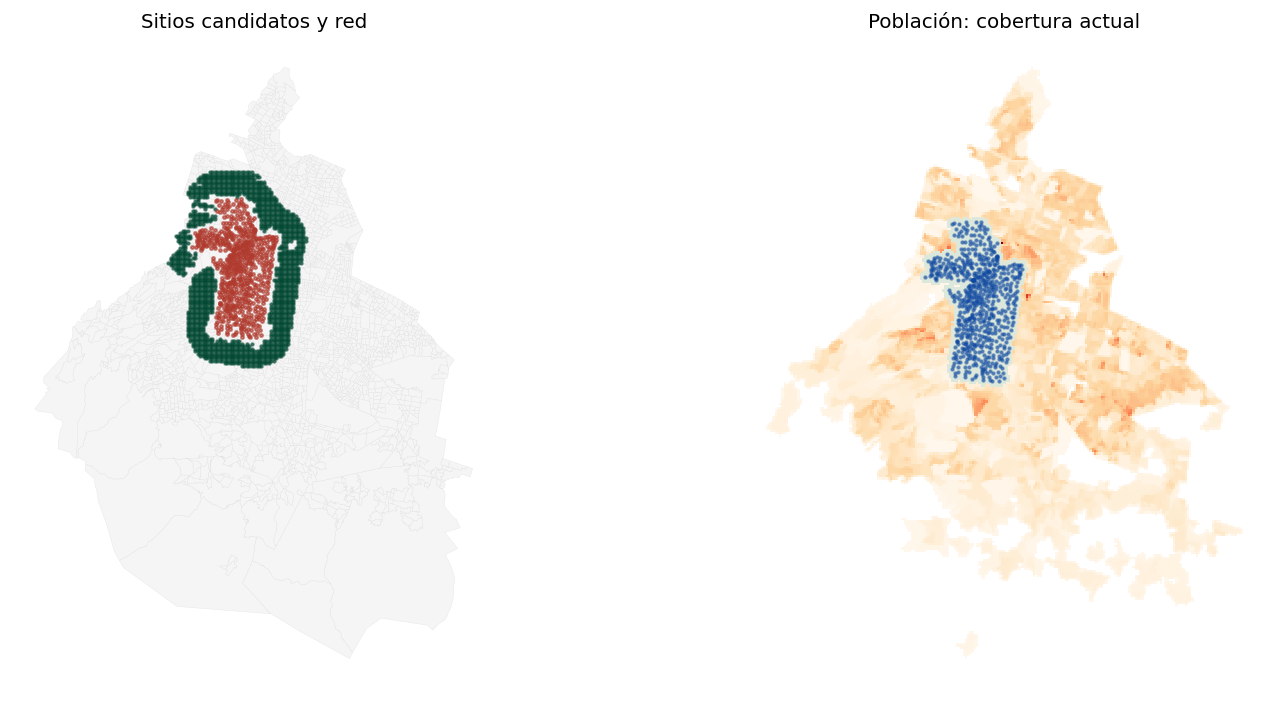

In [8]:
from V3.src import fe04_deployment as dep_mod
stations = data["frames"]["station_env"].to_crs(
    dep_mod.DEPLOY_CONFIG["metric_crs"])
sites, cells = result["deploy_sites"], result["deploy_cells"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
uni = data["frames"]["features"].to_crs(dep_mod.DEPLOY_CONFIG["metric_crs"])
uni.plot(ax=axes[0], color="#F5F5F5", edgecolor="#DDDDDD", linewidth=0.15)
sites.plot(ax=axes[0], color=GREEN, markersize=2, alpha=0.6)
stations.plot(ax=axes[0], color=RED, markersize=3, alpha=0.6)
axes[0].set_axis_off(); axes[0].set_title("Sitios candidatos y red")
cells.loc[cells.covered_existing].plot(ax=axes[1], color="#DCE8DC",
                                       edgecolor="none")
cells.loc[~cells.covered_existing & cells["pop"].gt(0)].plot(
    ax=axes[1], column="pop", cmap="OrRd", edgecolor="none")
stations.plot(ax=axes[1], color=BLUE, markersize=2, alpha=0.5)
axes[1].set_axis_off(); axes[1].set_title("Población: cobertura actual")
plt.tight_layout(); plt.show()

In [9]:
report_path = stage_results(V3_DIR, data, result)
display(Markdown("**Cierre.** Arnés de validación y contrato de "
                 "despliegue común publicados con verificación de "
                 "integridad; ningún motor fue entrenado en este "
                 "cuaderno."))
display(JSON({"fe04_report_path": report_path.relative_to(V3_DIR).as_posix()}))

**Cierre.** Arnés de validación y contrato de despliegue común publicados con verificación de integridad; ningún motor fue entrenado en este cuaderno.

<IPython.core.display.JSON object>